<a href="https://colab.research.google.com/github/sulther/ai-in-cybersecurity-assignment-3/blob/main/ENSP355_Lab3_Krishna_Gaur_240101004.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Q1. CNN, RNN/LSTM and GAN Concept Matching (5 Marks)

| Model | Suitable data | Cyber-security example |
|---|---|---|
| CNN | Images / grid-like data | Malware image classification |
| RNN / LSTM | Sequences / logs / time series | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples |
| Dense Network | Small numeric feature table | Normal/Attack classification in this lab |

**Why is a dense network used here?**  
The dataset contains four numeric input features. A dense neural network is suitable for learning relationships among these tabular numeric values. CNNs are more suited to image-like inputs, RNN/LSTMs to sequences, and GANs to generating synthetic samples.

## Q2. Dataset Preparation, Split and Normalization (5 Marks)

The label uses **0 = Normal** and **1 = Attack**. We use a 75:25 train-test split and fit `StandardScaler` only on the training data. The same fitted scaler is then used for the test data and new records.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the supplied CSV. In Colab, upload simple_cyber_activity.csv when prompted.
csv_file = "simple_cyber_activity.csv"
if not os.path.exists(csv_file):
    try:
        from google.colab import files
        uploaded = files.upload()
        if csv_file not in uploaded:
            raise FileNotFoundError(
                f"Please upload the file named {csv_file} and run this cell again."
            )
    except ImportError:
        raise FileNotFoundError(
            f"Place {csv_file} in the same folder as this notebook, then rerun this cell."
        )

df = pd.read_csv(csv_file)
display(df.head())
print("Dataset shape:", df.shape)
print("\\nClass counts (0 = Normal, 1 = Attack):")
print(df["label"].value_counts().sort_index())

,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0


Dataset shape: (100, 6)
\nClass counts (0 = Normal, 1 = Attack):
label
0    75
1    25
Name: count, dtype: int64


In [2]:
features = [
    "failed_logins",
    "login_hour",
    "new_device",
    "data_transfer_mb"
]

X = df[features]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Training label counts:")
print(y_train.value_counts().sort_index())
print("Testing label counts:")
print(y_test.value_counts().sort_index())

Training shape: (75, 4)
Testing shape: (25, 4)
Training label counts:
label
0    56
1    19
Name: count, dtype: int64
Testing label counts:
label
0    19
1     6
Name: count, dtype: int64


**Normalization explanation:** StandardScaler transforms each feature to a comparable scale using the training-set mean and standard deviation. This prevents features with larger numeric magnitudes from dominating simply because of their units. Fitting the scaler only on training data avoids information leakage from the test set.

## Q3. Build and Train the Neural Network (10 Marks)

The required architecture is **4–8–4–1**: four input features, hidden layers with 8 and 4 ReLU neurons, and one sigmoid output neuron. The model is trained for 20 epochs using Adam and binary cross-entropy.

In [3]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.5000 - loss: 0.7768 - val_accuracy: 0.4000 - val_loss: 0.7807
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5000 - loss: 0.7635 - val_accuracy: 0.4000 - val_loss: 0.7626
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5000 - loss: 0.7527 - val_accuracy: 0.4667 - val_loss: 0.7466
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5167 - loss: 0.7430 - val_accuracy: 0.4667 - val_loss: 0.7320
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5167 - loss: 0.7344 - val_accuracy: 0.6667 - val_loss: 0.7190
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5500 - loss: 0.7263 - val_accuracy: 0.6667 - val_loss: 0.7071
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6000 - loss: 0.7185 - val_accuracy: 0.6667 - val_loss: 0.6956
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6000 - loss: 0.7109 - val_accuracy: 0.6667 - val_loss: 0.6840


**Definitions to record**

- **Epoch:** One complete pass through the training dataset.
- **Batch size:** Number of training samples processed before the model updates its weights.

Record the final training and validation accuracy from the training output above. Actual metrics can vary slightly between runs.

## Q4. Accuracy/Loss Curves and Test Evaluation (10 Marks)

Accuracy measures the proportion of correct classifications. Loss measures prediction error according to the selected loss function. A large gap between training and validation performance may indicate overfitting.

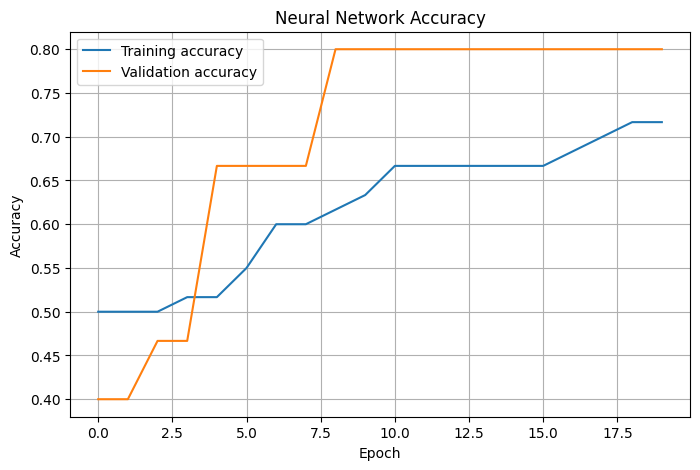

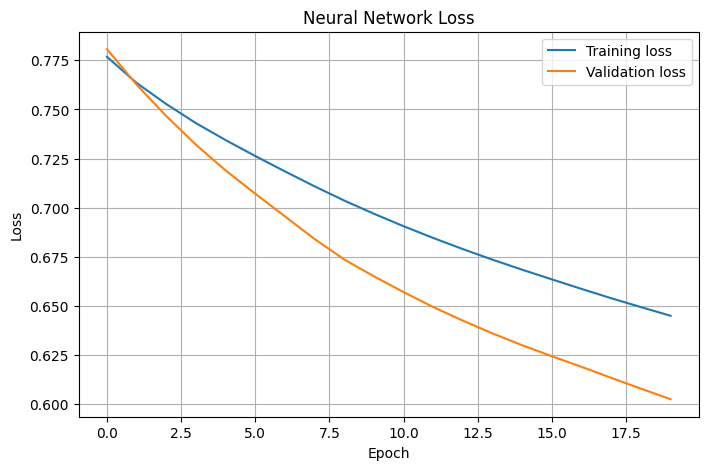

Test accuracy: 72.00%
Test loss: 0.6807


In [5]:
# Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

### Interpretation

After running the cell, inspect both graphs and write your observations:

- Did training accuracy increase over the epochs?
- Did training loss decrease?
- Did validation accuracy/loss follow a similar pattern?
- Is there a large gap between training and validation performance? If so, this may indicate overfitting; if both perform poorly, the model may be underfitting.

**Write your interpretation here after running the notebook.**

## Q5. New Predictions and Decision Tree Comparison (10 Marks)

The neural-network probability is classified as **Attack** when it is at least 0.50; otherwise it is **Normal**. The Decision Tree is trained on the same training split so that the test-set comparison is fair.

In [6]:
new_records = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 11, "new_device": 0, "data_transfer_mb": 35},
    {"failed_logins": 7, "login_hour": 1, "new_device": 1, "data_transfer_mb": 250},
    {"failed_logins": 2, "login_hour": 23, "new_device": 1, "data_transfer_mb": 850}
])

new_scaled = scaler.transform(new_records[features])
probabilities = model.predict(new_scaled, verbose=0).flatten()

results = new_records.copy()
results["nn_probability"] = probabilities.round(3)
results["nn_prediction"] = np.where(probabilities >= 0.50, "Attack", "Normal")

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

results["tree_prediction"] = np.where(
    tree.predict(new_records[features]) == 1,
    "Attack",
    "Normal"
)

print(f"Neural-network accuracy: {test_accuracy * 100:.2f}%")
print(f"Decision-tree accuracy: {tree_accuracy * 100:.2f}%")
display(results)

Neural-network accuracy: 72.00%
Decision-tree accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.380,Normal,Normal
1,7,1,1,250,0.384,Normal,Attack
2,2,23,1,850,0.362,Normal,Attack


### Comparison and conclusion

Compare the two test accuracies printed above. Discuss whether the neural network and Decision Tree agree on the three new records. A simpler Decision Tree may be preferable when its performance is similar because it is easier to interpret. Disagreement between models should be reviewed rather than treated as certainty.

**Write your conclusion here after running the notebook.**

## Submission Checklist

- [ ] Q1 concept-matching table and explanation
- [ ] Q2 dataset class counts and training/testing shapes
- [ ] Q3 model summary and 20-epoch training output
- [ ] Q4 accuracy and loss graphs
- [ ] Q4 test accuracy and test loss
- [ ] Q5 three new-record predictions
- [ ] Neural Network and Decision Tree accuracy comparison
- [ ] Written interpretation and conclusion
- [ ] Save/download the completed notebook with outputs

**Prepared by:** Krishna Gaur  
**Roll Number:** 240101004  
**Course:** B-Tech CSE (Core)